# Sales & Demand Forecasting
## Notebook 1: Data Understanding and Exploratory Data Analysis (EDA)

### Objective
Understand the historical sales data, check data quality, and explore overall sales trends and product-family performance.

### Business Goal
Identify patterns in historical sales that can support future sales forecasting and business planning.

## 1. Load the Datasets

Load the training dataset and store information to understand their structure, dimensions, and available columns.

In [8]:
import pandas as pd
from pathlib import Path

# Project paths
PROJECT_DIR = Path("..")
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"

PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Load datasets
train = pd.read_csv(RAW_DATA_DIR / "train.csv")
stores = pd.read_csv(RAW_DATA_DIR / "stores.csv")

# Basic inspection
print("Training data shape:", train.shape)
print("Store data shape:", stores.shape)

display(train.head())
display(stores.head())

Training data shape: (3000888, 6)
Store data shape: (54, 5)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


## 2. Data Quality Assessment

Check column data types, missing values, duplicate rows, date coverage, and the number of unique stores and product families.

These checks help determine whether any data cleaning is required before further analysis.

In [9]:
# Check data types and missing values
print("Training data info:")
train.info()

print("\nMissing values:")
print(train.isnull().sum())

print("\nDuplicate rows:", train.duplicated().sum())

print("\nDate range:")
print(train["date"].min(), "to", train["date"].max())

print("\nNumber of unique stores:", train["store_nbr"].nunique())
print("Number of product families:", train["family"].nunique())

Training data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB

Missing values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Duplicate rows: 0

Date range:
2013-01-01 to 2017-08-15

Number of unique stores: 54
Number of product families: 33


## 3. Daily Sales Trend

Aggregate sales across all stores and product families by date to examine overall sales trends over time.

The resulting time series provides an initial view of changes in sales levels and fluctuations across the observed period.

Daily sales shape: (1684, 2)


,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


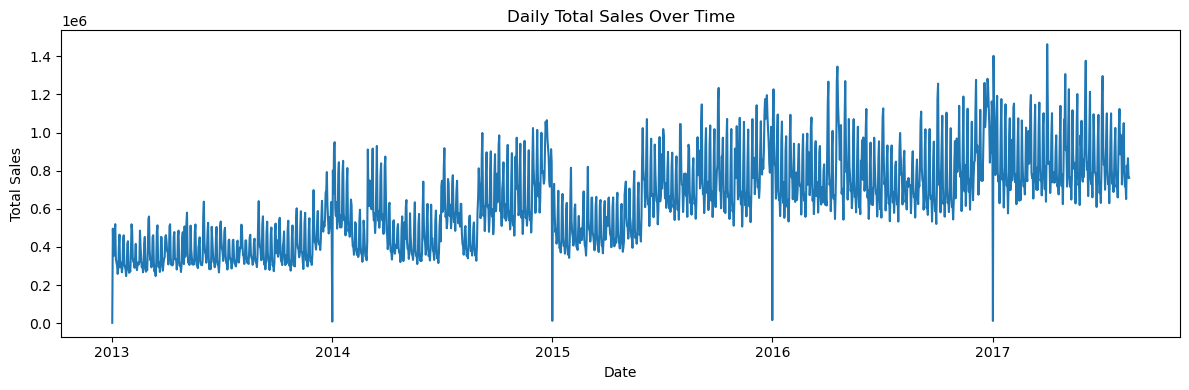

In [10]:
# Convert date column
train["date"] = pd.to_datetime(train["date"])

# Overall daily sales across all stores and product families
daily_sales = train.groupby("date")["sales"].sum().reset_index()

print("Daily sales shape:", daily_sales.shape)
display(daily_sales.head())

# Plot daily sales
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(daily_sales["date"], daily_sales["sales"])
plt.title("Daily Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

## 4. Yearly Sales Summary and Unusual Values

Summarize annual sales totals, average daily sales, and minimum and maximum daily sales.

Inspect the dates with the lowest recorded sales to identify unusual observations that may require careful interpretation.

Annual totals should be interpreted cautiously because 2017 contains data only through August 15.

In [11]:
# Total sales by year
daily_sales["year"] = daily_sales["date"].dt.year

yearly_sales = daily_sales.groupby("year")["sales"].agg(
    ["sum", "mean", "min", "max"]
).round(2)

display(yearly_sales)

# Inspect the lowest-sales dates
display(daily_sales.nsmallest(10, "sales"))

,sum,mean,min,max
year,,,,
2013,1.404190e+08,385766.52,2511.62,792865.28
2014,2.094742e+08,575478.70,8602.07,1064977.97
2015,2.408801e+08,661758.52,12773.62,1234130.94
2016,2.886545e+08,790834.31,16433.39,1345920.60
2017,1.942171e+08,855581.80,12082.50,1463083.96


,date,sales,year
0,2013-01-01,2511.618999,2013
364,2014-01-01,8602.065404,2014
1457,2017-01-01,12082.500997,2017
728,2015-01-01,12773.616980,2015
1092,2016-01-01,16433.394000,2016
23,2013-01-24,247245.690995,2013
72,2013-03-14,247541.420096,2013
9,2013-01-10,258982.003049,2013
28,2013-01-29,264488.818076,2013
177,2013-06-27,266525.458966,2013


## 5. Weekly Sales Trend

Aggregate daily sales into weekly totals to make the overall trend easier to examine.

Weekly aggregation reduces some day-to-day fluctuations while retaining changes in sales levels over time. The final week is incomplete because the dataset ends on August 15, 2017.

Weekly sales shape: (242, 2)


,date,sales
0,2013-01-06,2.211570e+06
1,2013-01-13,2.373618e+06
2,2013-01-20,2.368007e+06
3,2013-01-27,2.272165e+06
4,2013-02-03,2.476891e+06


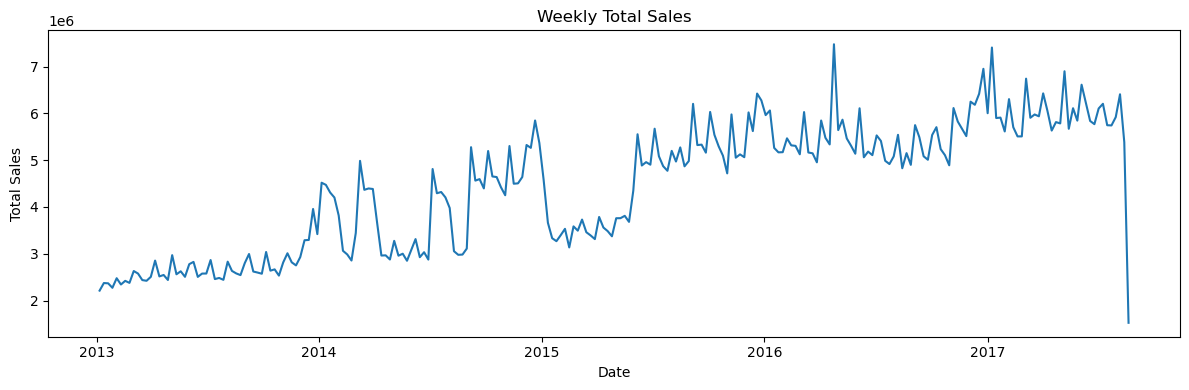

In [12]:
# Create weekly total sales
weekly_sales = (
    train.set_index("date")["sales"]
    .resample("W") 
    .sum()
    .reset_index()
)

weekly_sales.columns = ["date", "sales"]

print("Weekly sales shape:", weekly_sales.shape)
display(weekly_sales.head())

# Plot weekly sales
plt.figure(figsize=(12, 4))
plt.plot(weekly_sales["date"], weekly_sales["sales"])
plt.title("Weekly Total Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [13]:
# Save weekly sales dataset
weekly_sales.to_csv(
    PROCESSED_DATA_DIR / "weekly_sales.csv",
    index=False
)

print("Weekly sales dataset saved successfully.")

Weekly sales dataset saved successfully.


## 6. Sales by Product Family

Calculate total sales for each product family and identify the ten highest-performing families by total recorded sales.

This comparison highlights which product categories contribute the most sales across all stores and dates. Total sales do not represent average sales per day.

family
GROCERY I        3.434627e+08
BEVERAGES        2.169545e+08
PRODUCE          1.227047e+08
CLEANING         9.752129e+07
DAIRY            6.448771e+07
BREAD/BAKERY     4.213395e+07
POULTRY          3.187600e+07
MEATS            3.108647e+07
PERSONAL CARE    2.459205e+07
DELI             2.411032e+07
Name: sales, dtype: float64

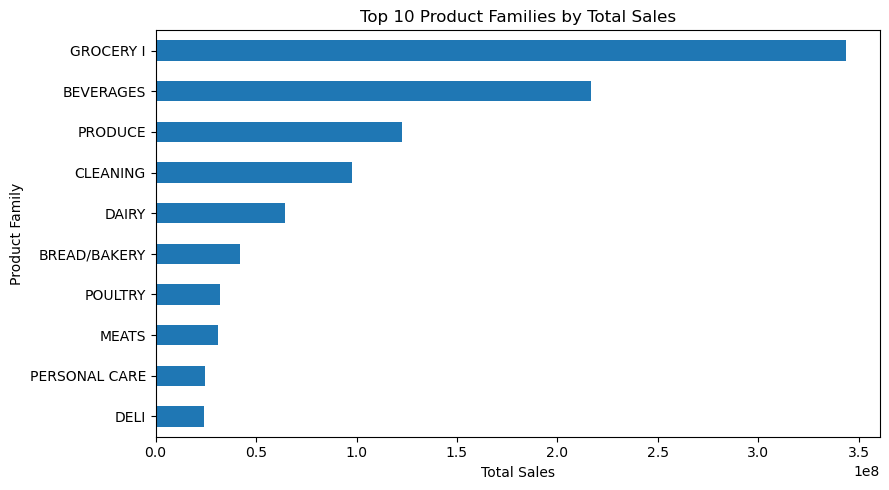

In [14]:
# Total sales by product family
family_sales = (
    train.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
)

display(family_sales.head(10).round(2))

# Plot top 10 product families
family_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top 10 Product Families by Total Sales"
)

plt.xlabel("Total Sales")
plt.ylabel("Product Family")
plt.tight_layout()
plt.show()

## 7. EDA Summary

- **Data quality:** The training dataset contains 3,000,888 rows and 6 columns, with no missing values or duplicate rows.
- **Date coverage:** The dataset spans January 1, 2013, to August 15, 2017.
- **Sales trend:** Daily and weekly sales show an overall upward trend, with substantial fluctuations over time.
- **Top product families:** GROCERY I recorded the highest total sales (approximately 343.5 million), followed by BEVERAGES (approximately 217.0 million) and PRODUCE (approximately 122.7 million).
- **Unusual observations:** January 1 has unusually low recorded sales in each year. The final week is incomplete because the dataset ends on August 15, 2017.

### Next Step

Proceed to feature engineering to prepare the date and sales data for forecasting.

No forecasting models are built in this notebook.